## Actividad 3: Análisis Exploratorio de Datos (EDA)

**Preguntas a responder con el análisis univariado:**
1. ¿Cuál es el rango de edad predominante y cómo se distribuyen los cargos mensuales? (Distribuciones numéricas)
2. ¿Existen valores atípicos evidentes en las horas trabajadas por semana o en la antigüedad de los clientes? (Boxplots)
3. ¿Cuáles son los sectores laborales y métodos de pago más comunes? (Gráficas categóricas)
4. ¿Qué tan desbalanceadas están nuestras variables objetivo? (Distribución de clases)

**Preguntas a responder con el análisis bivariado:**
5. ¿Existe multicolinealidad entre las variables numéricas de Telco? (Matriz de correlación)
6. ¿Cómo afecta el tipo de contrato a la tasa de abandono? (Relación atributo-objetivo)

In [11]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import os

sns.set_theme(style="whitegrid")

nombres_adult = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
                 'marital-status', 'occupation', 'relationship', 'race', 'sex',
                 'capital-gain', 'capital-loss', 'hours-per-week',
                 'native-country', 'income']

adult = pd.read_csv('../data/adult.csv', skipinitialspace=True, na_values='?',
                    header=None, names=nombres_adult)
telco = pd.read_csv('../data/telco_churn.csv')
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')

print(adult.shape, telco.shape)

(32561, 15) (7043, 21)


In [12]:
os.makedirs('../docs/figs', exist_ok=True)

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f'../docs/figs/{nombre}.png', dpi=150)
    plt.show()

In [13]:
# datos con nombres y categorías en español
adult_es = adult.rename(columns={
    'age': 'Edad',
    'workclass': 'Tipo de empleo',
    'fnlwgt': 'Peso muestral',
    'education': 'Nivel educativo',
    'education-num': 'Años de educación',
    'marital-status': 'Estado civil',
    'occupation': 'Ocupación',
    'relationship': 'Relación familiar',
    'race': 'Raza',
    'sex': 'Sexo',
    'capital-gain': 'Ganancia de capital',
    'capital-loss': 'Pérdida de capital',
    'hours-per-week': 'Horas por semana',
    'native-country': 'País de origen',
    'income': 'Ingreso',
})

adult_es['Sexo'] = adult_es['Sexo'].replace({'Male': 'Hombre', 'Female': 'Mujer'})

adult_es['Tipo de empleo'] = adult_es['Tipo de empleo'].replace({
    'Private': 'Privado',
    'Self-emp-not-inc': 'Autónomo (no inc.)',
    'Self-emp-inc': 'Autónomo (inc.)',
    'Federal-gov': 'Gobierno federal',
    'Local-gov': 'Gobierno local',
    'State-gov': 'Gobierno estatal',
    'Without-pay': 'Sin pago',
    'Never-worked': 'Nunca trabajó',
})

adult_es['Nivel educativo'] = adult_es['Nivel educativo'].replace({
    'Preschool': 'Preescolar', '1st-4th': '1.º a 4.º', '5th-6th': '5.º a 6.º',
    '7th-8th': '7.º a 8.º', '9th': '9.º', '10th': '10.º', '11th': '11.º',
    '12th': '12.º', 'HS-grad': 'Preparatoria',
    'Some-college': 'Universidad incompleta',
    'Assoc-voc': 'Técnico (vocacional)', 'Assoc-acdm': 'Técnico (académico)',
    'Bachelors': 'Licenciatura', 'Prof-school': 'Escuela profesional',
    'Masters': 'Maestría', 'Doctorate': 'Doctorado',
})

telco_es = telco.rename(columns={
    'tenure': 'Antigüedad (meses)',
    'MonthlyCharges': 'Cargo mensual',
    'TotalCharges': 'Cargo total',
    'SeniorCitizen': 'Adulto mayor',
    'Contract': 'Contrato',
    'InternetService': 'Servicio de internet',
    'Churn': 'Abandono',
})

telco_es['Contrato'] = telco_es['Contrato'].replace({
    'Month-to-month': 'Mensual', 'One year': 'Un año', 'Two year': 'Dos años'})
telco_es['Servicio de internet'] = telco_es['Servicio de internet'].replace({
    'Fiber optic': 'Fibra óptica', 'No': 'Sin internet'})
telco_es['Abandono'] = telco_es['Abandono'].replace({'Yes': 'Sí', 'No': 'No'})

print(adult_es.columns.tolist())
print(telco_es[['Contrato', 'Servicio de internet', 'Abandono']].head())

['Edad', 'Tipo de empleo', 'Peso muestral', 'Nivel educativo', 'Años de educación', 'Estado civil', 'Ocupación', 'Relación familiar', 'Raza', 'Sexo', 'Ganancia de capital', 'Pérdida de capital', 'Horas por semana', 'País de origen', 'Ingreso']
  Contrato Servicio de internet Abandono
0  Mensual                  DSL       No
1   Un año                  DSL       No
2  Mensual                  DSL       Sí
3   Un año                  DSL       No
4  Mensual         Fibra óptica       Sí


In [14]:
def eda(df, nombre, num2, cat2, objetivo, rel):
    # 1) Dos distribuciones numéricas
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, c in zip(ax, num2):
        sns.histplot(df[c].dropna(), kde=True, ax=a)
        a.set_title(f'Distribución de {c}\n(asimetría = {df[c].skew():.2f})')
        a.set_xlabel(c)
        a.set_ylabel('Frecuencia')
    guardar(f'{nombre}_distribuciones')

    # 2) Dos boxplots frente a la clase
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for a, c in zip(ax, num2):
        sns.boxplot(data=df, x=objetivo, y=c, ax=a)
        a.set_title(f'Diagrama de caja de {c}\nsegún {objetivo}')
        a.set_xlabel(objetivo)
        a.set_ylabel(c)
    guardar(f'{nombre}_boxplots')

    # 3) Dos gráficas categóricas frente a la clase
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    for a, c in zip(ax, cat2):
        sns.countplot(data=df, y=c, hue=objetivo, ax=a)
        a.set_title(f'Frecuencia de {c} según {objetivo}')
        a.set_xlabel('Cantidad de registros')
        a.set_ylabel(c)
        a.legend(title=objetivo)
    guardar(f'{nombre}_categoricas')

    # 4) Matriz de correlación
    plt.figure(figsize=(7, 6))
    sns.heatmap(df.select_dtypes('number').corr(), annot=True,
                fmt='.2f', cmap='coolwarm', center=0)
    plt.title('Matriz de correlación entre variables numéricas')
    guardar(f'{nombre}_correlacion')

    # 5) Distribución de clases (con porcentaje)
    orden = df[objetivo].value_counts().index
    pct = df[objetivo].value_counts(normalize=True)[orden] * 100
    plt.figure(figsize=(4, 4))
    ax = sns.countplot(data=df, x=objetivo, order=orden)
    for p, v in zip(ax.patches, pct):
        ax.annotate(f'{v:.1f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom')
    plt.title(f'Distribución de la clase objetivo\n({objetivo})')
    plt.xlabel(objetivo)
    plt.ylabel('Cantidad de registros')
    guardar(f'{nombre}_clases')

    # 6) Relación atributo-objetivo (% de cada clase por categoría)
    tasa = pd.crosstab(df[rel], df[objetivo], normalize='index') * 100
    tasa = tasa.sort_values(tasa.columns[-1])
    tasa.plot(kind='bar', stacked=True, figsize=(8, 5))
    plt.xlabel(rel)
    plt.ylabel('Porcentaje (%)')
    plt.title(f'Porcentaje de {objetivo} según {rel}')
    plt.legend(title=objetivo)
    plt.xticks(rotation=45, ha='right')
    guardar(f'{nombre}_relacion')

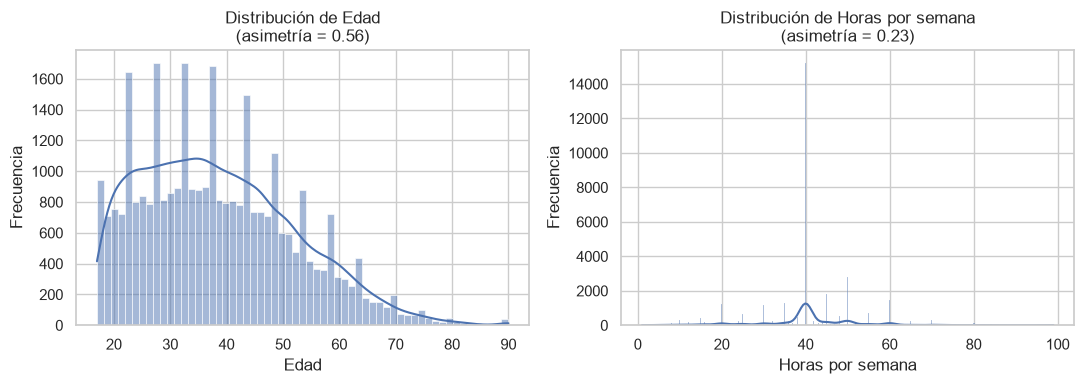

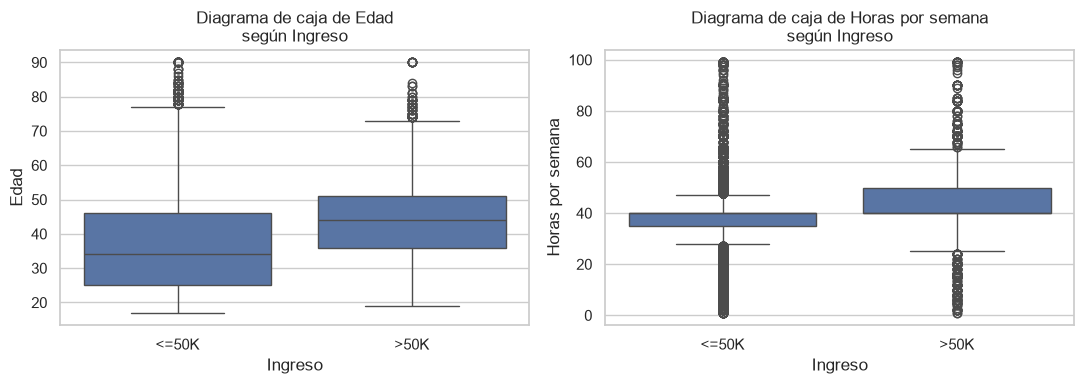

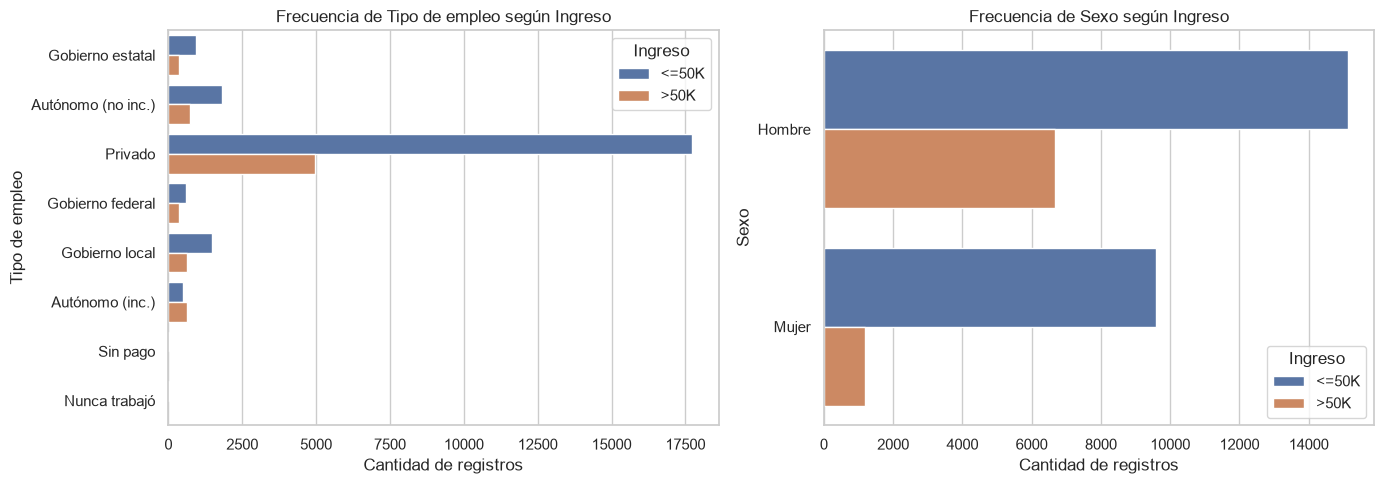

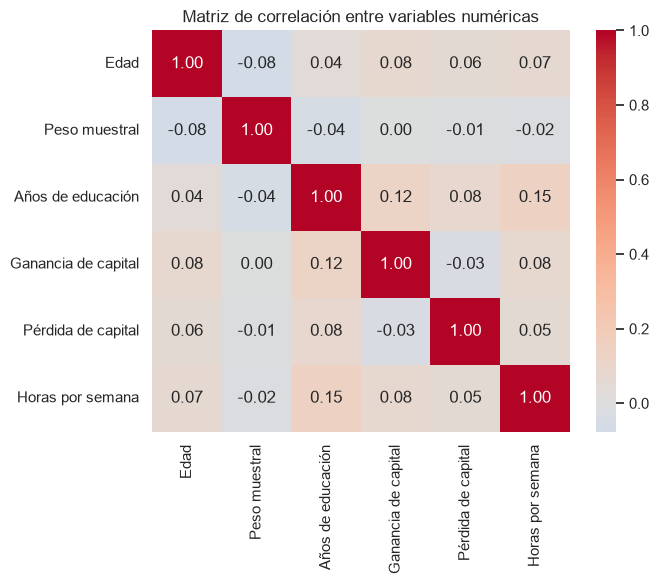

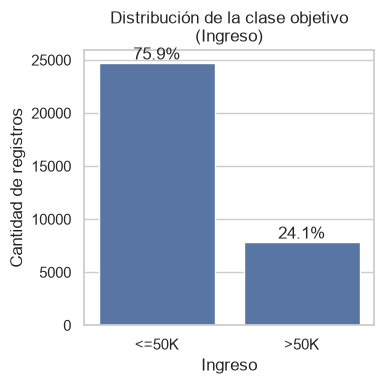

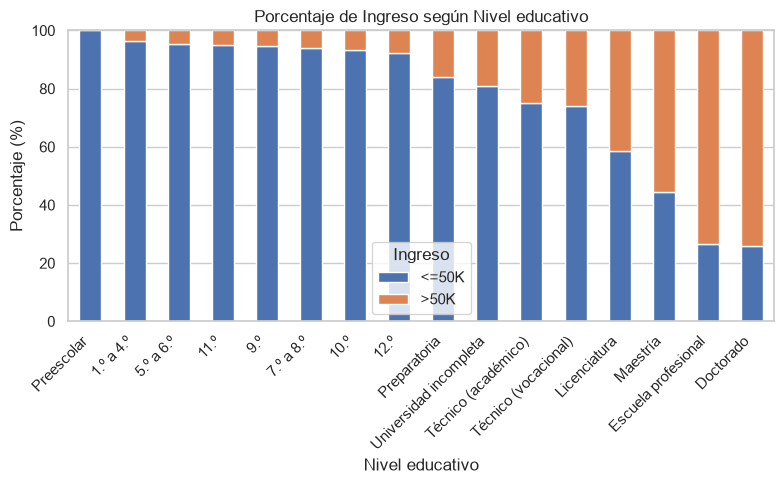

In [15]:
eda(adult_es, 'adult',
    num2=['Edad', 'Horas por semana'],
    cat2=['Tipo de empleo', 'Sexo'],
    objetivo='Ingreso',
    rel='Nivel educativo')

### 1. Distribuciones numéricas
**Pregunta:** ¿cómo se distribuyen la edad y las horas trabajadas?
**Observación:** la edad tiene asimetría moderada a la derecha (0.56) y un tope en 90 años. Las horas por semana se concentran en 40 h (casi la mitad de los registros), con picos en valores redondos.
**Conclusión:** ninguna variable es normal; hay concentraciones artificiales y valores extremos que conviene revisar en la etapa de outliers.

### 2. Diagramas de caja
**Pregunta:** ¿difieren la edad y las horas trabajadas entre quienes ganan más y menos de 50K?
**Observación:** la mediana de edad es mayor en `>50K` (~44 vs ~34) y también las horas (40–50 h vs 35–40 h). Ambas variables presentan outliers en las dos clases.
**Conclusión:** son variables informativas, pero con valores atípicos que se tratarán con winsorización.


### 3. Variables categóricas
**Pregunta:** ¿cómo se reparte el ingreso según el tipo de empleo y el sexo?
**Observación:** el sector privado domina el dataset. La proporción de `>50K` es ~31% en hombres y ~11% en mujeres, y el dataset tiene el doble de hombres.
**Conclusión:** existe una diferencia importante por sexo, que es un riesgo de sesgo y debe vigilarse en el modelado.


### 4. Matriz de correlación
**Pregunta:** ¿hay variables numéricas redundantes?
**Observación:** todas las correlaciones son menores a 0.15.
**Conclusión:** no hay multicolinealidad; esta matriz solo detecta relaciones lineales, por lo que pueden existir relaciones no lineales no capturadas.


### 5. Distribución de clases
**Pregunta:** ¿está balanceada la clase objetivo?
**Observación:** 75.9% `<=50K` y 24.1% `>50K`; IR ≈ 3.15.
**Conclusión:** como IR > 1.5, el dataset está desbalanceado y no se debe evaluar solo con accuracy.


### 6. Relación contrato-abandono
**Pregunta:** ¿cómo cambia la probabilidad de ganar más de 50K según la educación?
**Observación:** el porcentaje de `>50K` sube de menos de 10% en niveles básicos a más de 70% en Doctorate y Prof-school.
**Conclusión:** el nivel educativo es un predictor fuerte; las categorías con pocos registros (como Preschool) deben interpretarse con cautela.

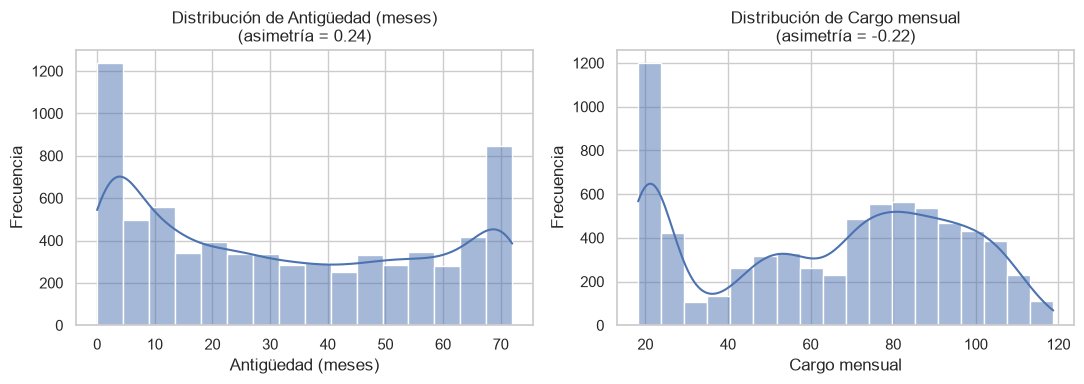

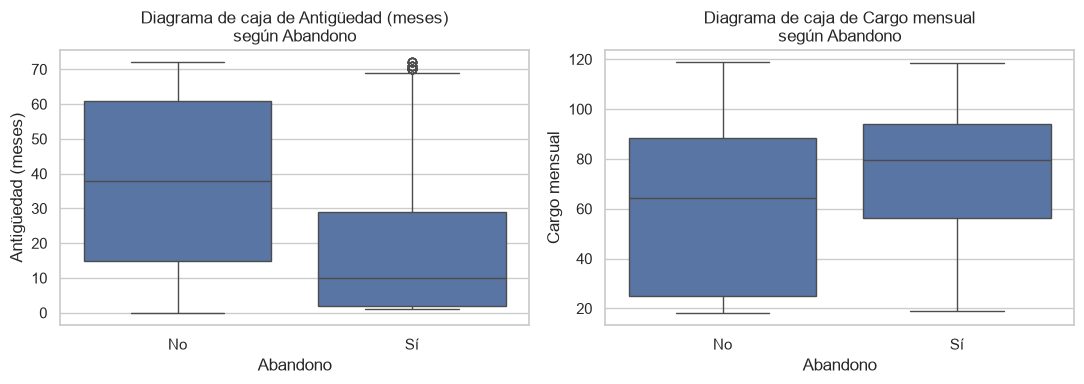

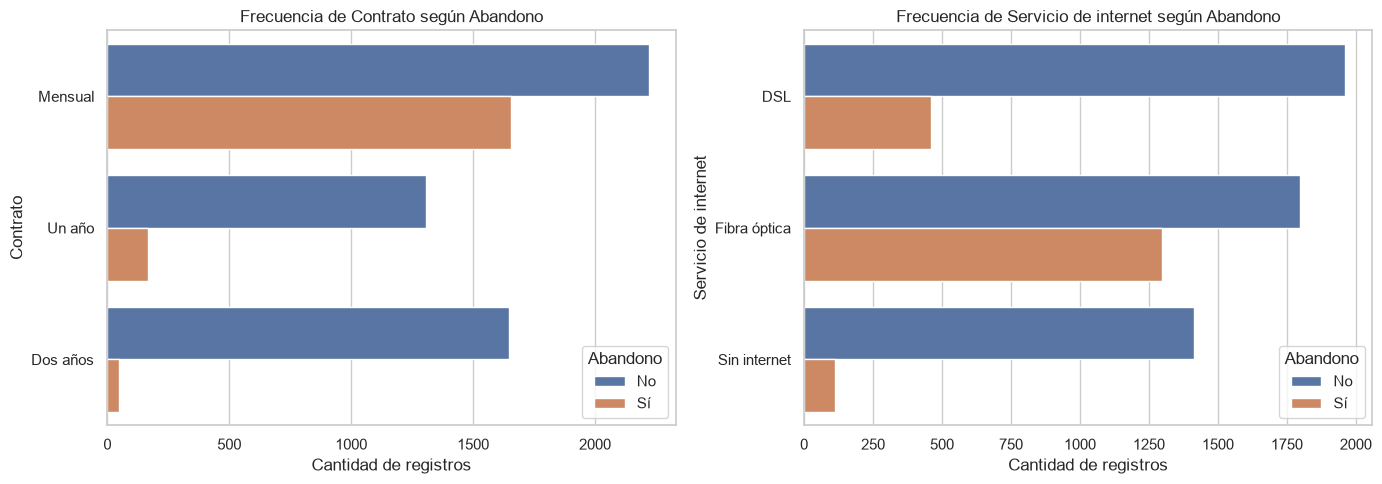

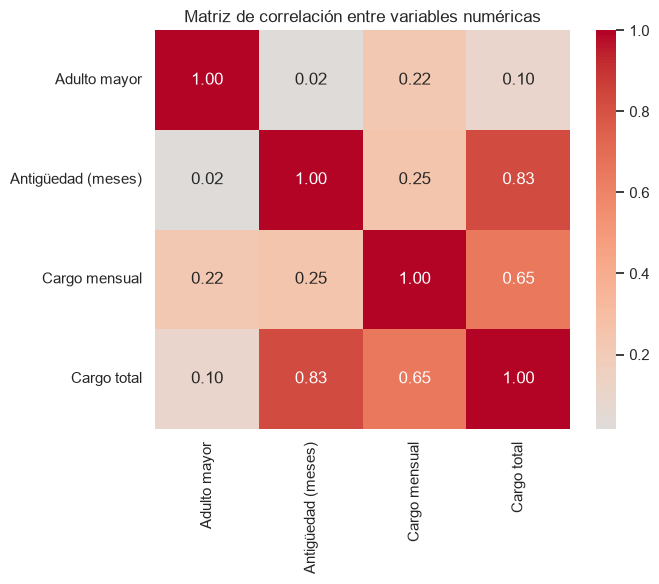

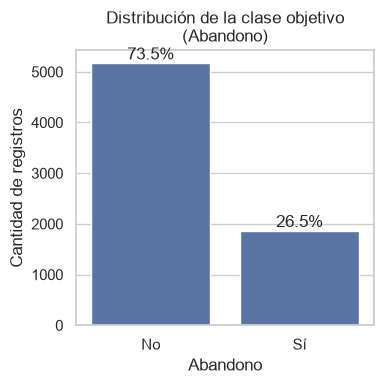

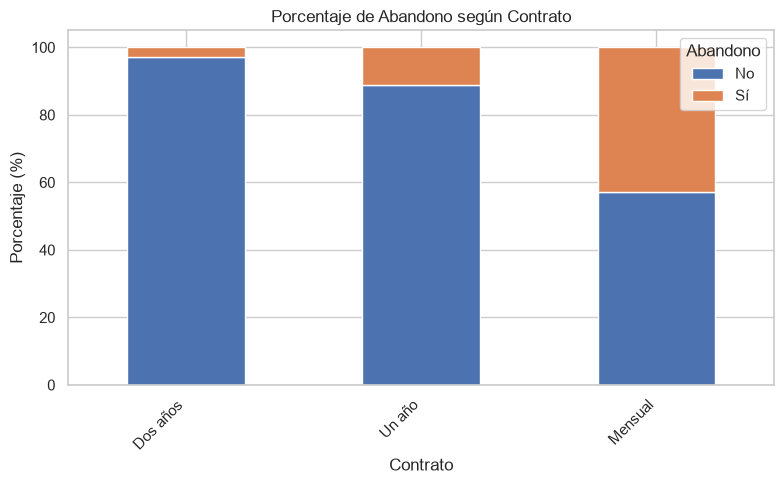

In [16]:
eda(telco_es, 'telco',
    num2=['Antigüedad (meses)', 'Cargo mensual'],
    cat2=['Contrato', 'Servicio de internet'],
    objetivo='Abandono',
    rel='Contrato')

### 1. Distribuciones numéricas
**Pregunta:** ¿cómo se distribuyen la antigüedad y el cargo mensual?
**Observación:** la antigüedad tiene forma de U, con picos en clientes nuevos (0 a 5 meses) y muy antiguos (~70 meses). El cargo mensual tiene un pico cerca de 20 y otra concentración entre 70 y 100. La asimetría es baja, pero ambas variables son bimodales.
**Conclusión:** hay grupos de clientes distintos; la asimetría por sí sola no describe bien estas variables.

### 2. Diagramas de caja
**Pregunta:** ¿difieren la antigüedad y el cargo mensual entre quienes abandonan y quienes se quedan?
**Observación:** quienes abandonan tienen mediana de antigüedad de ~10 meses (vs ~38) y un cargo mensual mayor (~79 vs ~64). Solo se ven unos pocos outliers en antigüedad.
**Conclusión:** los clientes nuevos y con cargos altos tienen mayor riesgo de abandono; hay pocos outliers en este dataset.

### 3. Variables categóricas
**Pregunta:** ¿cómo se reparte el abandono según el contrato y el servicio de internet?
**Observación:** el contrato mensual concentra la mayoría de los abandonos. La fibra óptica tiene mucho más abandono (~42%) que DSL (~19%) y que sin internet (~7%).
**Conclusión:** el tipo de contrato y de servicio son variables relevantes para explicar el abandono.

### 4. Matriz de correlación
**Pregunta:** ¿hay variables numéricas redundantes?
**Observación:** `Cargo total` correlaciona 0.83 con la antigüedad y 0.65 con el cargo mensual.
**Conclusión:** el cargo total es en gran parte derivado de las otras dos, lo que implica redundancia; la matriz solo mide relaciones lineales.

### 5. Distribución de clases
**Pregunta:** ¿está balanceada la clase objetivo?
**Observación:** 73.5% `No` y 26.5% `Sí`; IR ≈ 2.77.
**Conclusión:** como IR > 1.5, el dataset está desbalanceado y no debe evaluarse solo con accuracy.

### 6. Relación contrato-abandono
**Pregunta:** ¿cómo cambia la probabilidad de abandono según el contrato?
**Observación:** abandono de ~43% en contrato mensual, ~11% en un año y ~3% en dos años.
**Conclusión:** el contrato es un predictor muy fuerte; a mayor duración, menor abandono.

In [17]:
PROC = '../data/processed'
tr_a = pd.read_csv(f'{PROC}/adult_train_imputado.csv')
te_a = pd.read_csv(f'{PROC}/adult_test_imputado.csv')
tr_t = pd.read_csv(f'{PROC}/telco_train_imputado.csv')
te_t = pd.read_csv(f'{PROC}/telco_test_imputado.csv')

NUM_A = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
NUM_T = ['tenure', 'MonthlyCharges', 'TotalCharges']

print('Adult  train/test:', tr_a.shape, te_a.shape)
print('Telco  train/test:', tr_t.shape, te_t.shape)

def resumen_outliers(df, cols, nombre):
    filas = []
    for c in cols:
        s = df[c]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = ((s < lim_inf) | (s > lim_sup)).sum()
        filas.append({
            'Variable': c,
            'Q1': q1, 'Q3': q3,
            'Límite inf. (IQR)': lim_inf,
            'Límite sup. (IQR)': lim_sup,
            'Outliers (IQR)': n,
            '% outliers': 100 * n / len(s),
            'P1': s.quantile(0.01),
            'P99': s.quantile(0.99),
            '% de ceros': 100 * (s == 0).mean(),
            'Asimetría': s.skew(),
        })
    print(f'--- {nombre} (solo train) ---')
    display(pd.DataFrame(filas).round(2))

resumen_outliers(tr_a, NUM_A, 'Adult Income')
resumen_outliers(tr_t, NUM_T, 'Telco Churn')

Adult  train/test: (26029, 16) (6508, 16)
Telco  train/test: (5634, 20) (1409, 20)
--- Adult Income (solo train) ---


,Variable,Q1,Q3,Límite inf. (IQR),Límite sup. (IQR),Outliers (IQR),% outliers,P1,P99,% de ceros,Asimetría
0,age,28.0,47.0,-0.5,75.5,187,0.72,17.0,74.00,0.00,0.56
1,education-num,9.0,12.0,4.5,16.5,952,3.66,3.0,16.00,0.00,-0.31
2,capital-gain,0.0,0.0,0.0,0.0,2174,8.35,0.0,15024.00,91.65,12.07
3,capital-loss,0.0,0.0,0.0,0.0,1204,4.63,0.0,1995.12,95.37,4.61
4,hours-per-week,40.0,45.0,32.5,52.5,7241,27.82,8.0,80.00,0.00,0.23


--- Telco Churn (solo train) ---


,Variable,Q1,Q3,Límite inf. (IQR),Límite sup. (IQR),Outliers (IQR),% outliers,P1,P99,% de ceros,Asimetría
0,tenure,9.00,55.00,-60.00,124.00,0,0.0,1.00,72.00,0.14,0.24
1,MonthlyCharges,35.66,90.00,-45.84,171.51,0,0.0,19.20,114.98,0.00,-0.22
2,TotalCharges,402.98,3835.82,-4746.30,8985.10,0,0.0,19.75,8039.77,0.14,0.95


In [18]:
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def limites_pct(s, p_inf=0.01, p_sup=0.99):
    return s.quantile(p_inf), s.quantile(p_sup)

def winsorizar(train, test, col, criterio):
    """Límites calculados solo con train; se aplican a train y test."""
    lo, hi = limites_iqr(train[col]) if criterio == 'iqr' else limites_pct(train[col])
    return train[col].clip(lo, hi), test[col].clip(lo, hi), lo, hi

NOMBRE_CRIT = {'iqr': 'IQR', 'pct': 'Percentiles 1-99'}

# Qué variables y con qué criterios
PLAN_A = {'age': ['iqr', 'pct'],
          'hours-per-week': ['iqr', 'pct'],
          'capital-gain': ['pct'],
          'capital-loss': ['pct']}
PLAN_T = {'tenure': ['iqr', 'pct'],
          'MonthlyCharges': ['iqr', 'pct'],
          'TotalCharges': ['iqr', 'pct']}

def tabla_antes_despues(tr, te, plan, nombre):
    filas = []
    for col, criterios in plan.items():
        s = tr[col]
        filas.append({'Variable': col, 'Versión': 'Original',
                      'Lím.inf': np.nan, 'Lím.sup': np.nan,
                      'Media': s.mean(), 'Mediana': s.median(),
                      'Desv.est': s.std(), 'Mín': s.min(), 'Máx': s.max(),
                      'Modif.': 0, '%Modif.': 0.0})
        for crit in criterios:
            w_tr, w_te, lo, hi = winsorizar(tr, te, col, crit)
            n = int((w_tr != s).sum())
            filas.append({'Variable': col, 'Versión': NOMBRE_CRIT[crit],
                          'Lím.inf': lo, 'Lím.sup': hi,
                          'Media': w_tr.mean(), 'Mediana': w_tr.median(),
                          'Desv.est': w_tr.std(), 'Mín': w_tr.min(), 'Máx': w_tr.max(),
                          'Modif.': n, '%Modif.': 100 * n / len(s)})
    print(f'\n=== {nombre}: estadísticos antes y después (train) ===')
    print(pd.DataFrame(filas).round(2).to_string(index=False))

tabla_antes_despues(tr_a, te_a, PLAN_A, 'Adult Income')
tabla_antes_despues(tr_t, te_t, PLAN_T, 'Telco Churn')


=== Adult Income: estadísticos antes y después (train) ===
      Variable          Versión  Lím.inf  Lím.sup   Media  Mediana  Desv.est  Mín      Máx  Modif.  %Modif.
           age         Original      NaN      NaN   38.55     37.0     13.65 17.0    90.00       0     0.00
           age              IQR     -0.5    75.50   38.51     37.0     13.52 17.0    75.50     187     0.72
           age Percentiles 1-99     17.0    74.00   38.50     37.0     13.49 17.0    74.00     223     0.86
hours-per-week         Original      NaN      NaN   40.43     40.0     12.43  1.0    99.00       0     0.00
hours-per-week              IQR     32.5    52.50   41.20     40.0      6.20 32.5    52.50    7241    27.82
hours-per-week Percentiles 1-99      8.0    80.00   40.38     40.0     12.01  8.0    80.00     422     1.62
  capital-gain         Original      NaN      NaN 1064.60      0.0   7303.52  0.0 99999.00       0     0.00
  capital-gain Percentiles 1-99      0.0 15024.00  632.19      0.0   2516.86

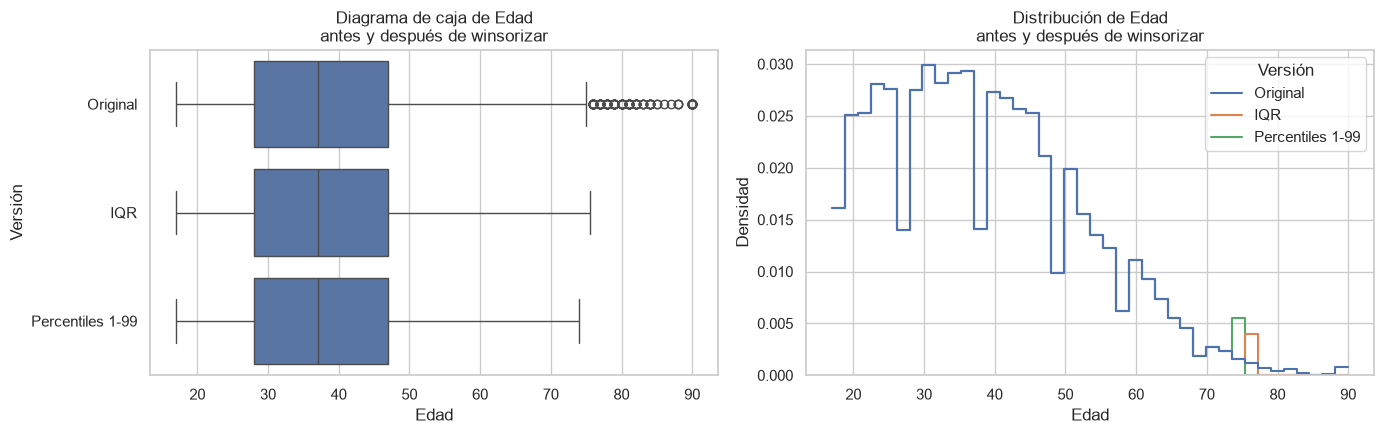

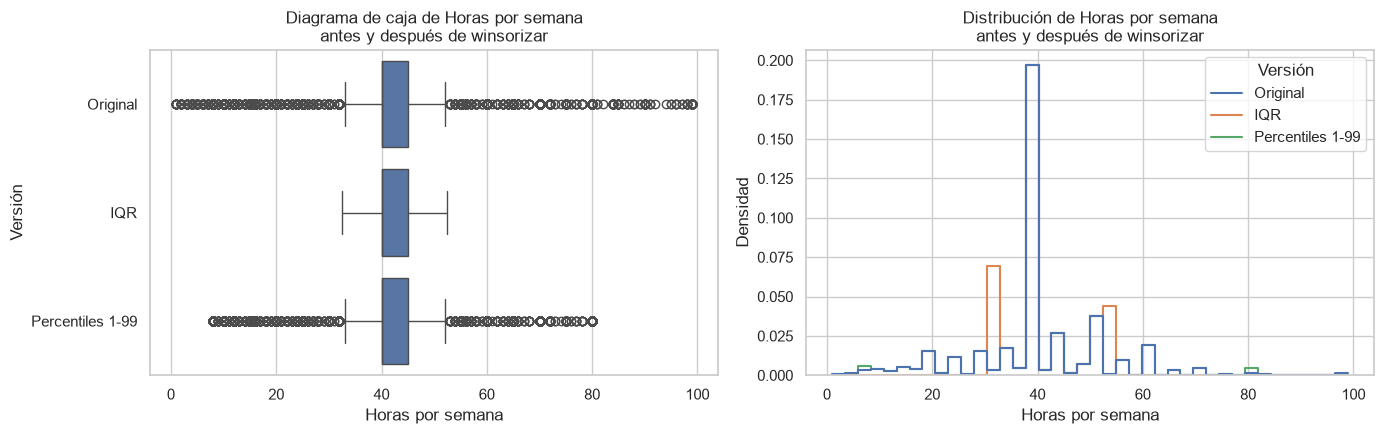

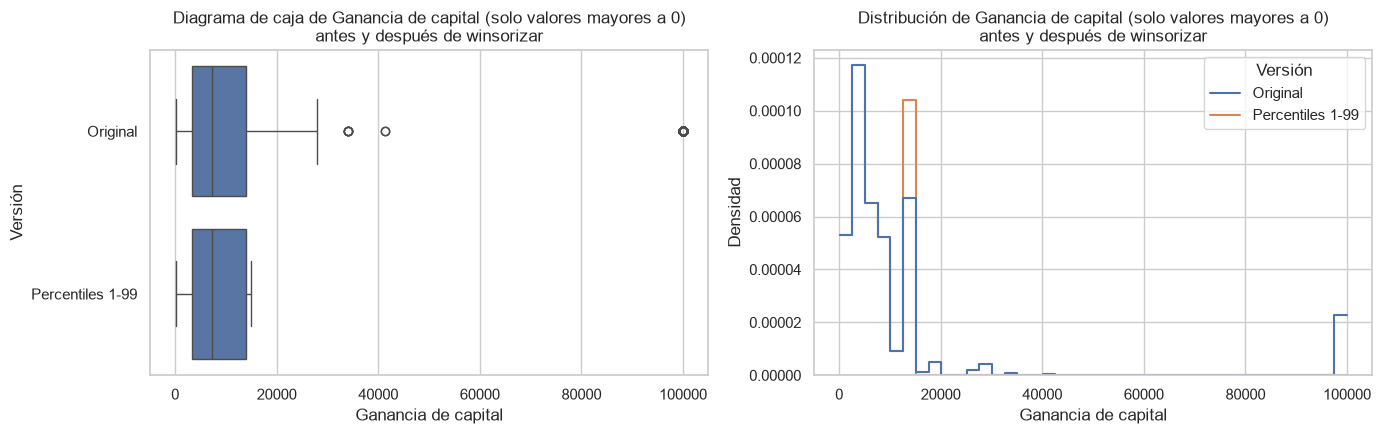

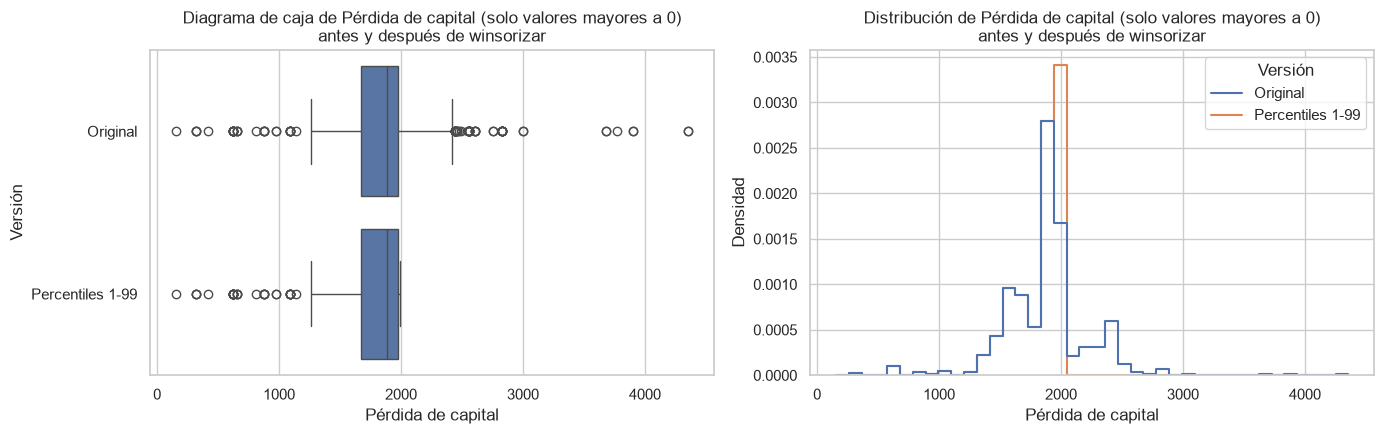

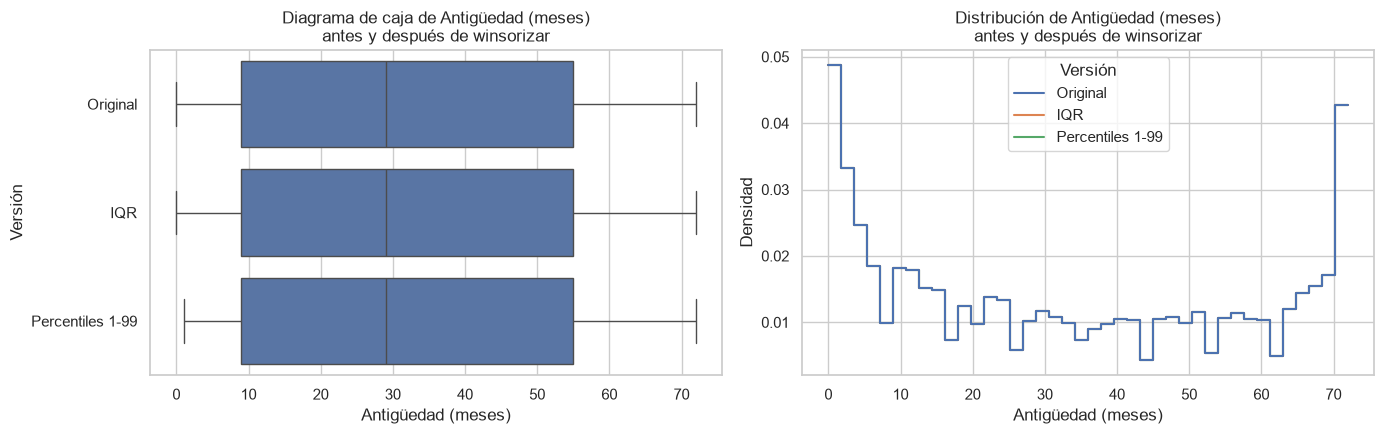

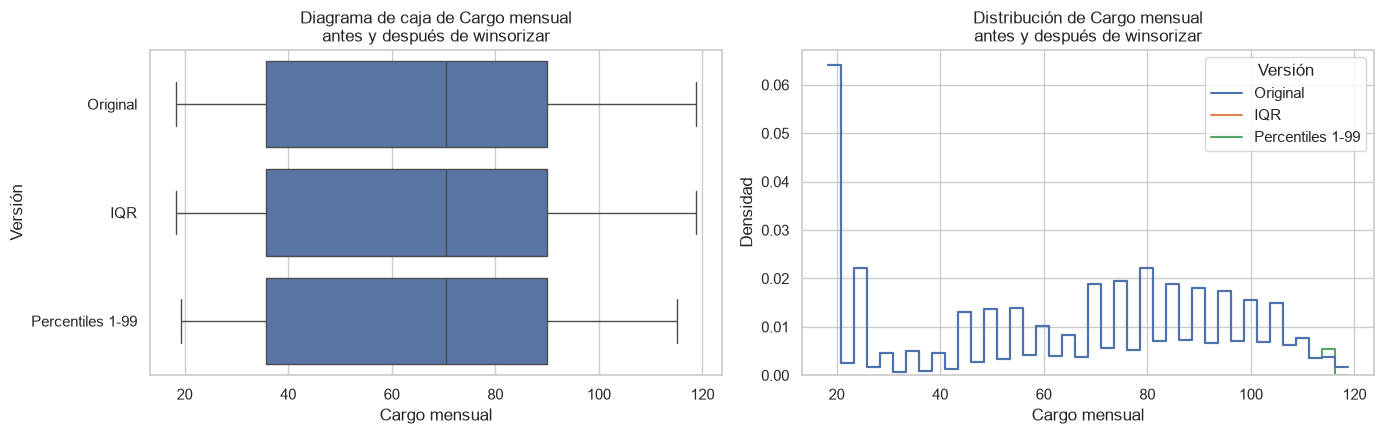

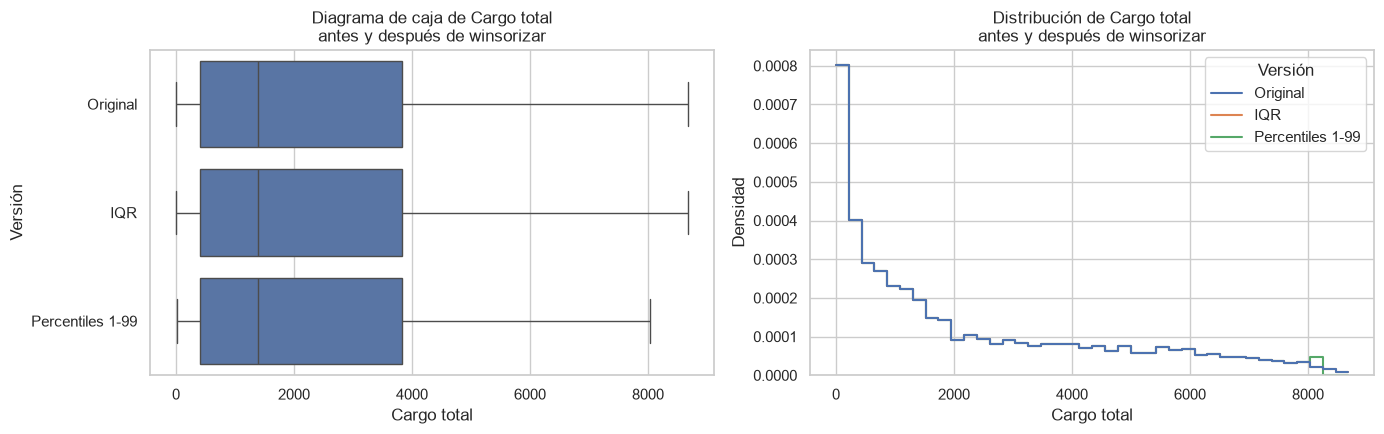

In [19]:
ETIQ = {'age': 'Edad', 'hours-per-week': 'Horas por semana',
        'capital-gain': 'Ganancia de capital', 'capital-loss': 'Pérdida de capital',
        'tenure': 'Antigüedad (meses)', 'MonthlyCharges': 'Cargo mensual',
        'TotalCharges': 'Cargo total'}

def graficas_antes_despues(tr, col, criterios, prefijo, solo_positivos=False):
    etiqueta = ETIQ.get(col, col)
    versiones = {'Original': tr[col]}
    for crit in criterios:
        lo, hi = limites_iqr(tr[col]) if crit == 'iqr' else limites_pct(tr[col])
        versiones[NOMBRE_CRIT[crit]] = tr[col].clip(lo, hi)
    largo = pd.concat([pd.DataFrame({'Valor': s, 'Versión': k})
                       for k, s in versiones.items()])
    sufijo = ' (solo valores mayores a 0)' if solo_positivos else ''
    if solo_positivos:
        largo = largo[largo['Valor'] > 0]

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    sns.boxplot(data=largo, x='Valor', y='Versión', ax=ax[0])
    ax[0].set_title(f'Diagrama de caja de {etiqueta}{sufijo}\nantes y después de winsorizar')
    ax[0].set_xlabel(etiqueta)
    ax[0].set_ylabel('Versión')
    sns.histplot(data=largo, x='Valor', hue='Versión', element='step', fill=False,
                 stat='density', common_norm=False, bins=40, ax=ax[1])
    ax[1].set_title(f'Distribución de {etiqueta}{sufijo}\nantes y después de winsorizar')
    ax[1].set_xlabel(etiqueta)
    ax[1].set_ylabel('Densidad')
    guardar(f'{prefijo}_{col}_antes_despues')

for col, crit in PLAN_A.items():
    graficas_antes_despues(tr_a, col, crit, 'adult',
                           solo_positivos=col in ('capital-gain', 'capital-loss'))
for col, crit in PLAN_T.items():
    graficas_antes_despues(tr_t, col, crit, 'telco')

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score)

def crear_modelo(X):
    num = X.select_dtypes('number').columns.tolist()
    cat = X.select_dtypes(exclude='number').columns.tolist()
    prep = ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat)])
    return Pipeline([('prep', prep), ('modelo', LogisticRegression(max_iter=2000))])

def aplicar_plan(tr, te, plan):
    tr, te = tr.copy(), te.copy()
    for col, crit in plan.items():
        tr[col], te[col], _, _ = winsorizar(tr, te, col, crit)
    return tr, te

def evaluar(tr, te):
    Xtr, ytr = tr.drop(columns='target'), tr['target']
    Xte, yte = te.drop(columns='target'), te['target']
    pipe = crear_modelo(Xtr).fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    prob = pipe.predict_proba(Xte)[:, 1]
    return {'precision': precision_score(yte, pred),
            'recall': recall_score(yte, pred),
            'f1': f1_score(yte, pred),
            'pr_auc': average_precision_score(yte, prob)}

escenarios = {
    'Adult': (tr_a, te_a, {
        'Sin winsorizar': {},
        'IQR (age, hours)': {'age': 'iqr', 'hours-per-week': 'iqr'},
        'Percentiles 1-99': {'age': 'pct', 'hours-per-week': 'pct',
                             'capital-gain': 'pct', 'capital-loss': 'pct'}}),
    'Telco': (tr_t, te_t, {
        'Sin winsorizar': {},
        'IQR': {c: 'iqr' for c in NUM_T},
        'Percentiles 1-99': {c: 'pct' for c in NUM_T}}),
}

filas = []
for ds, (tr, te, versiones) in escenarios.items():
    for nombre, plan in versiones.items():
        tr_w, te_w = aplicar_plan(tr, te, plan)
        filas.append({'dataset': ds, 'versión': nombre, **evaluar(tr_w, te_w)})

res = pd.DataFrame(filas)
print(res.round(4).to_string(index=False))
res.round(4).to_csv('../docs/figs/outliers_desempeno_modelo.csv', index=False)

dataset          versión  precision  recall     f1  pr_auc
  Adult   Sin winsorizar     0.7362  0.6231 0.6750  0.7821
  Adult IQR (age, hours)     0.7400  0.6263 0.6784  0.7850
  Adult Percentiles 1-99     0.7387  0.6256 0.6775  0.7829
  Telco   Sin winsorizar     0.6562  0.5561 0.6020  0.6355
  Telco              IQR     0.6562  0.5561 0.6020  0.6355
  Telco Percentiles 1-99     0.6562  0.5561 0.6020  0.6354


## Actividad 5: Detección y tratamiento de outliers

**Método:** winsorización con dos criterios: 1 rango intercuartílico (IQR, límites Q1 − 1.5·IQR y Q3 + 1.5·IQR) y 2 percentiles extremos 1 y 99. Los límites se calculan **solo con el conjunto de entrenamiento** y se aplican igual al de prueba, para evitar fuga de información. Se parte de los datos ya imputados de la Actividad 4. El modelo de comparación es la misma regresión logística de la Actividad 4, con el mismo split.

### 5.1 Resultados por variable Adult Income

**Edad.** El IQR modifica 187 registros (0.72%) y los percentiles 223 (0.86%). La media casi no cambia (38.55 a 38.50) y la desviación estándar baja de 13.65 a ~13.5. El efecto se limita a la cola de mayores de 75 años.

**Horas por semana.** El IQR modifica 7,241 registros (27.82%) y reduce la desviación estándar a la mitad (12.43 a 6.20). Esto ocurre porque casi la mitad de los registros trabaja 40 horas, lo que deja un IQR de solo 5 horas. Además crea concentraciones artificiales en 32.5 y 52.5. Los percentiles modifican solo 422 registros (1.62%) y conservan la variabilidad (desviación de 12.01).

**Ganancia de capital.** El 91.65% de los valores son 0, así que Q1 = Q3 = 0 y los límites del IQR colapsan en [0, 0]; el criterio IQR **no es aplicable**. Con percentiles se modifica el 0.77% de los registros: el máximo baja de 99,999 a 15,024, la media de 1,064.60 a 632.19 y la desviación estándar de 7,303.52 a 2,516.86.

**Pérdida de capital.** Mismo problema que la ganancia de capital (95.37% de ceros). Con percentiles se modifica el 1.0% de los registros y el máximo baja de 4,356 a 1,995.

**Años de educación.** No se winsorizó: es una variable ordinal discreta (1 a 16) y sus valores bajos son niveles educativos reales, no errores de captura.

### 5.2 Resultados por variable Telco Churn

Con el criterio IQR **no hay outliers** en antigüedad, cargo mensual ni cargo total (0 registros modificados). Con percentiles se recorta entre 0.14% y 1.93% de los registros, sin cambios apreciables en media ni desviación estándar. Además, el percentil 1 de la antigüedad (1) y del cargo total (19.75) modificaría los clientes con `tenure = 0`, cuyo valor 0 fue imputado deliberadamente en la Actividad 4 por ser faltantes estructurales.

### 5.3 Efecto en el desempeño del clasificador

| Dataset | Versión | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|---|
| Adult | Sin winsorizar | 0.7362 | 0.6231 | 0.6750 | 0.7821 |
| Adult | IQR (age, hours) | 0.7400 | 0.6263 | 0.6784 | 0.7850 |
| Adult | Percentiles 1-99 | 0.7387 | 0.6256 | 0.6775 | 0.7829 |
| Telco | Sin winsorizar | 0.6562 | 0.5561 | 0.6020 | 0.6355 |
| Telco | IQR | 0.6562 | 0.5561 | 0.6020 | 0.6355 |
| Telco | Percentiles 1-99 | 0.6562 | 0.5561 | 0.6020 | 0.6354 |

Las diferencias son menores a 0.004 en todas las métricas, por lo que no hay evidencia de que la winsorización mejore o empeore el clasificador. En Telco el IQR no modifica ningún dato, por eso las métricas son idénticas.

### 5.4 Decisión y conclusiones

- **Adult:** se winsorizan `age`, `hours-per-week`, `capital-gain` y `capital-loss` con **percentiles 1-99**. El IQR se descarta porque en `hours-per-week` altera el 27.82% de los datos y crea picos artificiales, y en las variables de capital es inaplicable por la cantidad de ceros.
- **Telco:** **no se winsoriza**. No hay outliers según el IQR y los percentiles solo recortarían valores legítimos (y desharían la imputación de `tenure = 0`).
- La decisión se basa en el efecto sobre la distribución, no en las métricas del modelo, que no cambian de forma relevante.
- **Limitaciones:** se usó un solo modelo (regresión logística, poco sensible a valores extremos una vez estandarizados) y un solo split; con más variabilidad (validación cruzada) podrían apreciarse diferencias.

In [21]:
PROC = '../data/processed'

# Decisión final de la Actividad 5
PLAN_FINAL_ADULT = {'age': 'pct', 'hours-per-week': 'pct',
                    'capital-gain': 'pct', 'capital-loss': 'pct'}
# Telco: no se winsoriza (sin cambios)

# --- Adult: límites calculados con train, aplicados a train y test ---
tr_a_w, te_a_w = tr_a.copy(), te_a.copy()
for col, crit in PLAN_FINAL_ADULT.items():
    tr_a_w[col], te_a_w[col], lo, hi = winsorizar(tr_a, te_a, col, crit)
    print(f'{col}: límites [{lo:.2f}, {hi:.2f}] | '
          f'modificados train: {(tr_a_w[col] != tr_a[col]).sum()} | '
          f'test: {(te_a_w[col] != te_a[col]).sum()}')

# --- Telco: se guarda igual que la versión imputada, para tener el mismo formato ---
tr_t_w, te_t_w = tr_t.copy(), te_t.copy()

# Verificaciones
assert tr_a_w.shape == tr_a.shape and te_a_w.shape == te_a.shape
assert tr_a_w.isna().sum().sum() == 0 and te_a_w.isna().sum().sum() == 0
assert (tr_a_w['target'] == tr_a['target']).all()
assert (te_a_w['target'] == te_a['target']).all()

# Guardado (archivos nuevos, no se tocan los *_imputado.csv)
tr_a_w.to_csv(f'{PROC}/adult_train_winsor.csv', index=False)
te_a_w.to_csv(f'{PROC}/adult_test_winsor.csv', index=False)
tr_t_w.to_csv(f'{PROC}/telco_train_winsor.csv', index=False)
te_t_w.to_csv(f'{PROC}/telco_test_winsor.csv', index=False)

print('\nGuardados en', PROC)
print('Adult  train/test:', tr_a_w.shape, te_a_w.shape)
print('Telco  train/test:', tr_t_w.shape, te_t_w.shape)

age: límites [17.00, 74.00] | modificados train: 223 | test: 62
hours-per-week: límites [8.00, 80.00] | modificados train: 422 | test: 81
capital-gain: límites [0.00, 15024.00] | modificados train: 201 | test: 60
capital-loss: límites [0.00, 1995.12] | modificados train: 261 | test: 64

Guardados en ../data/processed
Adult  train/test: (26029, 16) (6508, 16)
Telco  train/test: (5634, 20) (1409, 20)
